## Task: Predict whether a client subscribes to a term deposit (y = yes is the positive class).

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import time

import warnings
from sklearn.exceptions import ConvergenceWarning


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

In [ ]:
#check the version of python, scikit-learn, and XGBOOST
import sys
print("Python version:", sys.version)
print("scikit-learn version:", sklearn.__version__)
print("xgboost version:", xgb.__version__)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
scikit-learn version: 1.6.1
xgboost version: 3.4.1


In [ ]:
!lscpu | grep "Model name"

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


In [ ]:
#upload file
from google.colab import files
uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full.csv


In [ ]:
# read csv file
import pandas as pd
df = pd.read_csv('bank-additional-full.csv', delimiter= ",")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Drop duration from the predictors. It is the completed call’s duration and is unavailable when making a prediction before that call. The dataset documentation explicitly flags this leakage risk.

# 01. Data Preparation

In [ ]:
#drop duration
df = df.drop(['duration'], axis=1)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#dataset dimension
df.shape

(41188, 20)

In [ ]:
print("Number of observations:", len(df))
print("Number of features:", df.shape[1] - 1)

Number of observations: 41188
Number of features: 19


In [ ]:
#Overall feature information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  object 
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null 

In [ ]:
#numerical features
df.describe()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [ ]:
#categorical features
df.describe(include="object")

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


In [ ]:
cat_preview = df.select_dtypes(include="object").columns.tolist()
print("\nCategorical columns:", cat_preview)
for c in cat_preview:
    n_unknown = (df[c] == "unknown").sum()
    if n_unknown:
        print(f"  {c}: {n_unknown} 'unknown' values ({n_unknown/len(df):.2%})")


Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']
  job: 330 'unknown' values (0.80%)
  marital: 80 'unknown' values (0.19%)
  education: 1731 'unknown' values (4.20%)
  default: 8597 'unknown' values (20.87%)
  housing: 990 'unknown' values (2.40%)
  loan: 990 'unknown' values (2.40%)



Positive class ('y'=='yes') proportion: 0.1127  (4640 of 41188 rows)


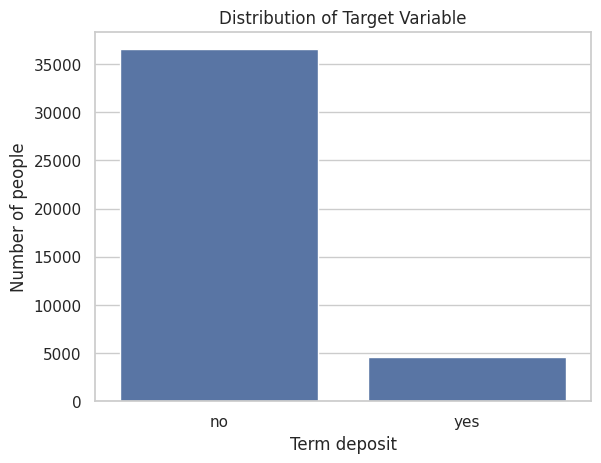

In [ ]:
#target variable distribution
pos_rate = (df["y"] == "yes").mean()
print(f"\nPositive class ('y'=='yes') proportion: {pos_rate:.4f}  "
      f"({(df['y']=='yes').sum()} of {len(df)} rows)")

sns.countplot(x= "y", data = df)
plt.title("Distribution of Target Variable")
plt.xlabel('Term deposit')
plt.ylabel('Number of people')
plt.show()

In [ ]:
print(f"\npdays = 999 (never previously contacted): "
      f"{(df['pdays']==999).sum()} rows ({(df['pdays']==999).mean():.2%})")


pdays = 999 (never previously contacted): 39673 rows (96.32%)


Feeding 999 directly into a scaled MLP would distort the numeric scale (treating "never contacted" as "contacted 999 days ago, extremely long"). I kept `pdays` as a
  raw numeric feature (trees can split around 999 natively) and add an explicit binary
  indicator `was_previously_contacted = (pdays != 999)` so both models can use "no prior contact"
  as a clean categorical signal independent of the numeric scale.

In [ ]:
df_clean = df.copy()
y = (df_clean["y"] == "yes").astype(int)
X = df_clean.drop(columns=["y"])

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

# was_previously_contacted is computed from the *original* pdays, before the sentinel is replaced.
X["was_previously_contacted"] = (X["pdays"] != 999).astype(int)
num_cols.append("was_previously_contacted")

# 999 is a sentinel ("never contacted"), not a real elapsed-time value -- replace with NaN so it
# is median-imputed (on the training split only) rather than treated as a 999-day gap.
X["pdays"] = X["pdays"].replace(999, np.nan)

print(f"{len(cat_cols)} categorical columns, {len(num_cols)} numeric columns (incl. engineered flag)")
print("Categorical:", cat_cols)
print("Numeric:", num_cols)
print(f"pdays missing (was 999): {X['pdays'].isna().sum()} rows")


10 categorical columns, 10 numeric columns (incl. engineered flag)
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_previously_contacted']
pdays missing (was 999): 39673 rows


### Stratified 70/15/15 training/validation/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size= 0.15 / 0.85, random_state=42, stratify=y_train)


for name, Xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s}: n={len(Xs):6d}  positive rate={ys.mean():.4f}")

train: n= 28830  positive rate=0.1127
val  : n=  6179  positive rate=0.1126
test : n=  6179  positive rate=0.1126


### Preprocessing

In [ ]:
num_impute_tree = SimpleImputer(strategy="median")
num_impute_scale_mlp = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

In [ ]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

tree_pre = ColumnTransformer([
    ("cat", ohe, cat_cols),
    ("num", num_impute_tree, num_cols),
])
mlp_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", num_impute_scale_mlp, num_cols),
])

t0 = time.perf_counter()
Xtr_tree = tree_pre.fit_transform(X_train)
t_pre_tree = time.perf_counter() - t0
Xva_tree = tree_pre.transform(X_val)
Xte_tree = tree_pre.transform(X_test)
feat_names_tree = tree_pre.get_feature_names_out()

t0 = time.perf_counter()
Xtr_mlp = mlp_pre.fit_transform(X_train)
t_pre_mlp = time.perf_counter() - t0
Xva_mlp = mlp_pre.transform(X_val)
Xte_mlp = mlp_pre.transform(X_test)

ytr, yva, yte = y_train.values, y_val.values, y_test.values

print(f"Tree-pipeline feature matrix: {Xtr_tree.shape}, fit+transform time = {t_pre_tree:.3f}s")
print(f"MLP-pipeline feature matrix:  {Xtr_mlp.shape}, fit+transform time = {t_pre_mlp:.3f}s")



Tree-pipeline feature matrix: (28830, 63), fit+transform time = 0.207s
MLP-pipeline feature matrix:  (28830, 63), fit+transform time = 0.192s


# 02. Gradient Boosted Trees (GBDT)

In [ ]:
# Training GBDT
def train_gbdt(Xtr, ytr, Xva, yva, learning_rate=0.1, max_depth=4,
               n_estimators=1000, subsample=1.0, reg_lambda=1.0,
               reg_alpha=0.0, early_stopping_rounds=30):

    model = xgb.XGBClassifier(
        tree_method="hist",
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        subsample=subsample,
        reg_lambda=reg_lambda,
        reg_alpha=reg_alpha,
        eval_metric="logloss",
        early_stopping_rounds=early_stopping_rounds,
        random_state=42,
        n_jobs=-1,
    )

    t0 = time.perf_counter()

    model.fit(
        Xtr, ytr,
        eval_set=[(Xtr, ytr), (Xva, yva)],
        verbose=False
    )

    fit_time = time.perf_counter() - t0

    val_proba = model.predict_proba(Xva)[:, 1]

    return (
        model,
        fit_time,
        average_precision_score(yva, val_proba),
        log_loss(yva, val_proba)
    )


In [ ]:
gbdt_results = []

lr_runs = []
for lr in [0.01, 0.1, 0.3]:
    model, ft, ap, ll = train_gbdt(Xtr_tree, ytr, Xva_tree, yva, learning_rate=lr)
    row = {"stage": "learning_rate", "learning_rate": lr, "max_depth": 4, "subsample": 1.0,
           "reg_lambda": 1.0, "val_ap": ap, "val_logloss": ll, "fit_time_s": ft,
           "best_iteration": model.best_iteration}
    lr_runs.append(row)
gbdt_results += lr_runs
best_lr = max(lr_runs, key=lambda r: r["val_ap"])["learning_rate"]


#best learning_rate = the one that gives the highest validation Average Precision (AP)
print(f"Best learning rate: {best_lr}")

Best learning rate: 0.1


In [ ]:
#max depth
depth_runs = []
for depth in [3, 5, 7]:
    model, ft, ap, ll = train_gbdt(Xtr_tree, ytr, Xva_tree, yva, learning_rate=best_lr, max_depth=depth)
    row = {"stage": "max_depth", "learning_rate": best_lr, "max_depth": depth, "subsample": 1.0,
           "reg_lambda": 1.0, "val_ap": ap, "val_logloss": ll, "fit_time_s": ft,
           "best_iteration": model.best_iteration}
    depth_runs.append(row)
gbdt_results += depth_runs

best_depth = max(depth_runs, key=lambda r: r["val_ap"])["max_depth"]

print(f"Best max_depth: {best_depth}")

Best max_depth: 5


In [ ]:
#subsample (regularization)
sub_runs = []
for sub in [0.6, 0.8, 1.0]:
    model, ft, ap, ll = train_gbdt(Xtr_tree, ytr, Xva_tree, yva, learning_rate=best_lr,
                                    max_depth=best_depth, subsample=sub)
    row = {"stage": "subsample", "learning_rate": best_lr, "max_depth": best_depth, "subsample": sub,
           "reg_lambda": 1.0, "val_ap": ap, "val_logloss": ll, "fit_time_s": ft,
           "best_iteration": model.best_iteration}
    sub_runs.append(row)
gbdt_results += sub_runs
best_sub = max(sub_runs, key=lambda r: r["val_ap"])["subsample"]

print(f"Best max_subsample: {best_sub}")

Best max_subsample: 0.8


In [ ]:
gbdt_table = pd.DataFrame(gbdt_results)
gbdt_table

,stage,learning_rate,max_depth,subsample,reg_lambda,val_ap,val_logloss,fit_time_s,best_iteration
0,learning_rate,0.01,4,1.0,1.0,0.457686,0.276476,5.305333,462
1,learning_rate,0.10,4,1.0,1.0,0.458284,0.276287,0.711265,61
2,learning_rate,0.30,4,1.0,1.0,0.456185,0.277046,0.439693,24
3,max_depth,0.10,3,1.0,1.0,0.456411,0.276499,0.983442,116
4,max_depth,0.10,5,1.0,1.0,0.457241,0.276427,0.580453,31
5,max_depth,0.10,7,1.0,1.0,0.456128,0.275779,0.699689,28
6,subsample,0.10,5,0.6,1.0,0.456892,0.276357,0.573344,31
7,subsample,0.10,5,0.8,1.0,0.463549,0.275842,0.603402,30
8,subsample,0.10,5,1.0,1.0,0.457241,0.276427,0.528214,31


In [ ]:
gbdt_best_cfg = {"learning_rate": best_lr, "max_depth": best_depth, "subsample": best_sub,
                 "reg_lambda": 1.0}


gbdt_model, gbdt_fit_time, gbdt_val_ap, gbdt_val_ll = train_gbdt(
    Xtr_tree, ytr, Xva_tree, yva, **gbdt_best_cfg
)
print(f"Validation AP: {gbdt_val_ap:.4f}   Validation log loss: {gbdt_val_ll:.4f}")
print(f"Best iteration (early stopping): {gbdt_model.best_iteration} / "
      f"n_estimators limit = {gbdt_model.get_params()['n_estimators']}")
print(f"Fit time: {gbdt_fit_time:.3f}s")


Validation AP: 0.4635   Validation log loss: 0.2758
Best iteration (early stopping): 30 / n_estimators limit = 1000
Fit time: 1.883s


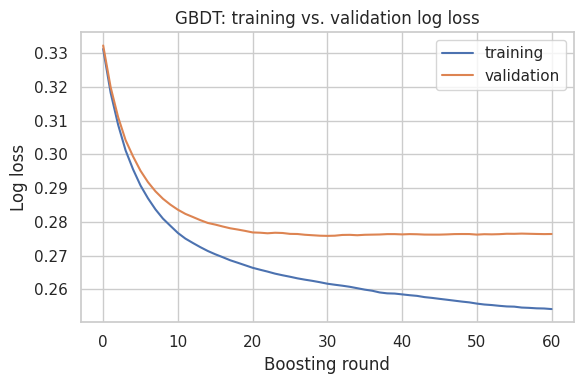

In [ ]:
evals = gbdt_model.evals_result()
#training vs validation log loss
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(evals["validation_0"]["logloss"], label="training")
ax.plot(evals["validation_1"]["logloss"], label="validation")
ax.set_xlabel("Boosting round")
ax.set_ylabel("Log loss")
ax.set_title("GBDT: training vs. validation log loss")
ax.legend()
fig.tight_layout()
plt.show()

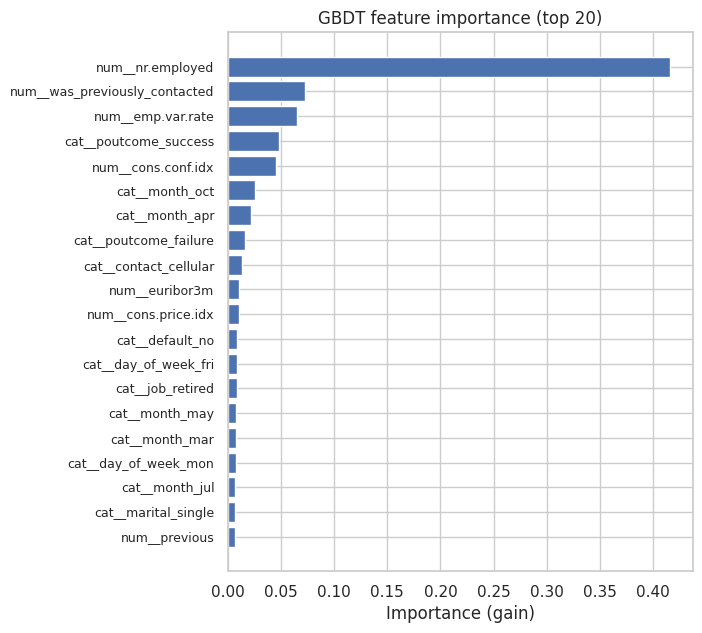

In [ ]:
#feature-importance plot
importances = gbdt_model.feature_importances_
order = np.argsort(importances)[::-1][:20]

fig, ax = plt.subplots(figsize=(6,7))
ax.barh(range(20), importances[order][::-1])
ax.set_yticks(range(len(order)))
ax.set_yticklabels([feat_names_tree[i] for i in order[::-1]], fontsize=9)
ax.set_xlabel("Importance (gain)")
ax.set_title("GBDT feature importance (top 20)")
plt.show()

# 03. Multi-Layer Perceptron (MLP)

In [ ]:
#Train sklearn.neural_network.MLPClassifier with solver = "adam".
def train_mlp(Xtr, ytr, Xva, yva, hidden_layer_sizes=(128, 64), learning_rate_init=1e-3,
              alpha=1e-4, activation="relu", max_iter=200):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model = MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes, solver="adam",
            learning_rate_init=learning_rate_init, alpha=alpha, activation=activation,
            max_iter=max_iter, early_stopping=False, random_state=42,
        )
        t0 = time.perf_counter()
        model.fit(Xtr, ytr)
        fit_time = time.perf_counter() - t0
    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )
    converged = not convergence_warning
    val_proba = model.predict_proba(Xva)[:, 1]
    return model, fit_time, average_precision_score(yva, val_proba), log_loss(yva, val_proba), converged


mlp_results = []

In [ ]:
#layers
archs = [(64,), (128, 64), (128, 64, 32)]
arch_runs = []
for arch in archs:
    model, ft, ap, ll, conv = train_mlp(Xtr_mlp, ytr, Xva_mlp, yva, hidden_layer_sizes=arch)
    arch_runs.append({"stage": "architecture", "hidden_layer_sizes": str(arch),
                       "learning_rate_init": 1e-3, "alpha": 1e-4, "activation": "relu", "val_ap": ap, "val_logloss": ll,
                       "fit_time_s": ft, "n_iter": model.n_iter_, "converged": conv})
mlp_results += arch_runs
best_arch_str = max(arch_runs, key=lambda r: r["val_ap"])["hidden_layer_sizes"]
best_arch = archs[[str(a) for a in archs].index(best_arch_str)]

print(f"Best architecture structure: {best_arch}")

Best architecture structure: (64,)


In [ ]:
#learning rate

lr_runs = []
for lr in [1e-3, 1e-4, 1e-5]:
    model, ft, ap, ll, conv = train_mlp(Xtr_mlp, ytr, Xva_mlp, yva, hidden_layer_sizes= best_arch, learning_rate_init=lr)
    lr_runs.append({"stage": "learning rate", "hidden_layer_sizes": best_arch_str,
                       "learning_rate_init": str(lr), "alpha": 1e-4, "activation": "relu", "val_ap": ap, "val_logloss": ll,
                       "fit_time_s": ft, "n_iter": model.n_iter_, "converged": conv})

mlp_results += lr_runs
best_lr_mlp = max(lr_runs, key=lambda r: r["val_ap"])["learning_rate_init"]

print(f"Best learning rate: {best_lr_mlp}")

Best learning rate: 0.0001


In [ ]:
alpha_runs = []
for alpha in [1e-6, 1e-4, 1e-2]:
    model, ft, ap, ll, conv = train_mlp(Xtr_mlp, ytr, Xva_mlp, yva, hidden_layer_sizes=best_arch,
                                         learning_rate_init=float(best_lr_mlp), alpha=alpha)
    alpha_runs.append({"stage": "alpha", "hidden_layer_sizes": best_arch,
                       "learning_rate_init": float(best_lr_mlp), "activation": "relu", "alpha": alpha, "val_ap": ap, "val_logloss" : ll,
                        "fit_time_s": ft, "n_iter": model.n_iter_, "converged": conv})

mlp_results += alpha_runs
best_alpha = max(alpha_runs, key = lambda r: r["val_ap"])["alpha"]

print(f"Best alpha: {best_alpha}")

Best alpha: 0.01


In [ ]:
mlp_table = pd.DataFrame(mlp_results)
mlp_table

,stage,hidden_layer_sizes,learning_rate_init,alpha,activation,val_ap,val_logloss,fit_time_s,n_iter,converged
0,architecture,"(64,)",0.001,0.000100,relu,0.377732,0.327002,59.415678,200,False
1,architecture,"(128, 64)",0.001,0.000100,relu,0.278556,0.947203,90.069084,200,False
2,architecture,"(128, 64, 32)",0.001,0.000100,relu,0.326610,1.032961,65.717009,137,True
3,learning rate,"(64,)",0.001,0.000100,relu,0.377732,0.327002,35.946924,200,False
4,learning rate,"(64,)",0.0001,0.000100,relu,0.438055,0.282556,44.993477,117,True
5,learning rate,"(64,)",1e-05,0.000100,relu,0.417618,0.285515,19.505736,90,True
6,alpha,"(64,)",0.0001,0.000001,relu,0.437920,0.282595,34.729474,117,True
7,alpha,"(64,)",0.0001,0.000100,relu,0.438055,0.282556,20.120431,117,True
8,alpha,"(64,)",0.0001,0.010000,relu,0.438208,0.282389,20.958178,101,True


In [ ]:
mlp_best_cfg = {"hidden_layer_sizes": best_arch, "learning_rate_init": float(best_lr_mlp), "alpha": best_alpha}

print("Selected MLP configuration (highest validation AP):", mlp_best_cfg)

mlp_model, mlp_fit_time, mlp_val_ap, mlp_val_ll, mlp_converged = train_mlp(
    Xtr_mlp, ytr, Xva_mlp, yva, **mlp_best_cfg
)
print(f"Validation AP: {mlp_val_ap:.4f}   Validation log loss: {mlp_val_ll:.4f}")
print(f"n_iter_ = {mlp_model.n_iter_} / max_iter = 200   Converged: {mlp_converged}")
print(f"Fit time: {mlp_fit_time:.3f}s")

Selected MLP configuration (highest validation AP): {'hidden_layer_sizes': (64,), 'learning_rate_init': 0.0001, 'alpha': 0.01}
Validation AP: 0.4382   Validation log loss: 0.2824
n_iter_ = 101 / max_iter = 200   Converged: True
Fit time: 19.291s


### Training loss curve and validation performance vs. architecture

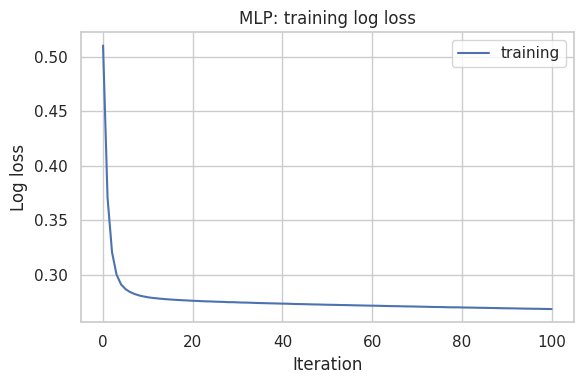

In [ ]:
### Training loss curve and validation performance vs. architecture
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(mlp_model.loss_curve_, label="training")
ax.set_xlabel("Iteration")
ax.set_ylabel("Log loss")
ax.set_title("MLP: training log loss")
ax.legend()
fig.tight_layout()
plt.show()

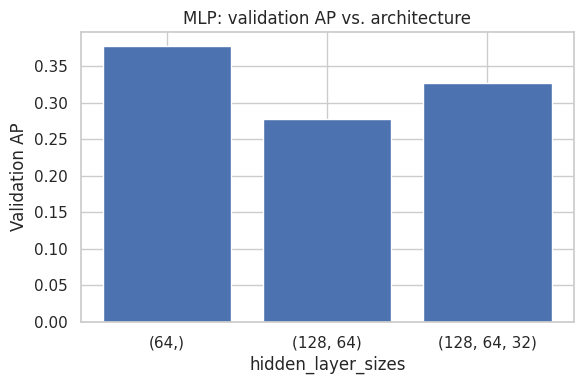

In [ ]:
## Validation Average Precision vs Architecture
fig, ax = plt.subplots(figsize=(6, 4))
labels = [r["hidden_layer_sizes"] for r in arch_runs]
aps = [r["val_ap"] for r in arch_runs]
ax.bar(labels, aps, color="#4C72B0")
ax.set_ylabel("Validation AP"); ax.set_xlabel("hidden_layer_sizes")
ax.set_title("MLP: validation AP vs. architecture")
fig.tight_layout()
plt.show()

## 04. Model Evaluation & Comparison

In [ ]:
def metrics_at_threshold(y_true, proba, thresh=0.5):
    pred = (proba >= thresh).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "AP": average_precision_score(y_true, proba),
    }

In [ ]:
gbdt_test_proba = gbdt_model.predict_proba(Xte_tree)[:, 1]
mlp_test_proba = mlp_model.predict_proba(Xte_mlp)[:, 1]
pos_rate_test = yte.mean()

gbdt_test_metrics = metrics_at_threshold(yte, gbdt_test_proba)
mlp_test_metrics = metrics_at_threshold(yte, mlp_test_proba)

comparison = pd.DataFrame({"GBDT": gbdt_test_metrics, "MLP": mlp_test_metrics}).round(4)
comparison.loc["Fit time (s)"] = [gbdt_fit_time, mlp_fit_time]
comparison.loc["Preprocessing time (s)"] = [t_pre_tree, t_pre_mlp]
print(f"Test positive-class proportion (reference level for PR plot): {pos_rate_test:.4f}")
comparison

Test positive-class proportion (reference level for PR plot): 0.1126


,GBDT,MLP
Accuracy,0.903700,0.902700
Precision,0.730600,0.723000
Recall,0.229900,0.221300
F1,0.349700,0.338800
AP,0.495400,0.477600
Fit time (s),1.882672,17.969815
Preprocessing time (s),0.207353,0.192016


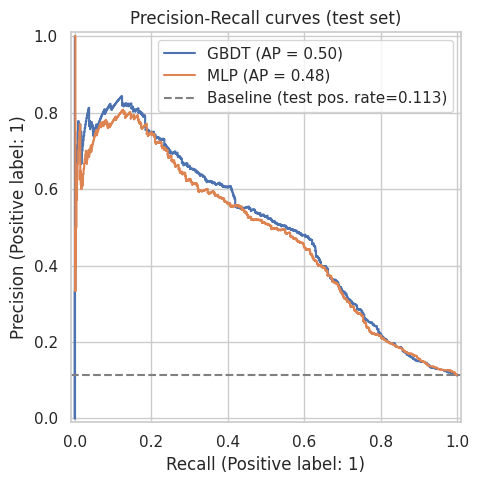

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(yte, gbdt_test_proba, ax=ax, name="GBDT")
PrecisionRecallDisplay.from_predictions(yte, mlp_test_proba, ax=ax, name="MLP")

ax.axhline(pos_rate_test, color="gray", linestyle="--",
           label=f"Baseline (test pos. rate={pos_rate_test:.3f})")

ax.legend()
ax.set_title("Precision-Recall curves (test set)")
fig.tight_layout()

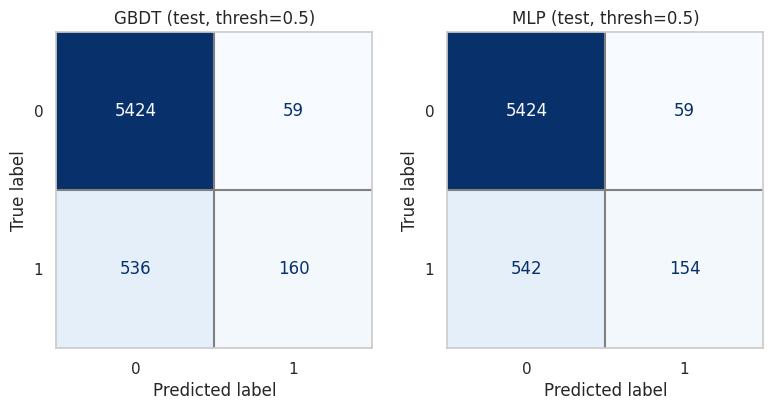

In [ ]:
from matplotlib import colormaps
list(colormaps)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
ConfusionMatrixDisplay.from_predictions(yte, (gbdt_test_proba >= 0.5).astype(int),
                                         ax=axes[0], cmap = "Blues", colorbar=False)
axes[0].set_title("GBDT (test, thresh=0.5)")
ConfusionMatrixDisplay.from_predictions(yte, (mlp_test_proba >= 0.5).astype(int),
                                         ax=axes[1], cmap = "Blues", colorbar=False)
axes[1].set_title("MLP (test, thresh=0.5)")
fig.tight_layout()
for ax in axes:
    ax.grid(False)
    ax.axhline(y=0.5, color="grey", linewidth=1.5)
    ax.axvline(x=0.5, color="grey", linewidth=1.5)